# 03. 모델 체크포인트 — 규칙 베이스라인 vs 머신러닝

**질문**: 머신러닝이 단순한 규칙보다 부족 발생을 더 잘 맞히는가? (주제를 유지할지 판단하는 11/22 체크포인트)

**설계**
- 대상: 현재 재고 ≥ 3인 행 (이미 부족한 곳은 제외) → 목표: h시간 뒤 재고 ≤ 2
- 분할: **시간 순서**. 학습 = 10/1~12/2, 검증 = 12/3~12/10(임계값·조기종료용), 테스트 = 12/11~12/31. 경계마다 3시간 간격을 둔다(미래 정보 누수 방지). 무작위 분할은 쓰지 않는다.
- 평가: 사건이 2~5%뿐인 불균형 문제라 **정확도만 보면 의미가 없다**(전부 '안 부족'이라 해도 95% 이상). PR-AUC, Precision, Recall, F1을 함께 본다.
- 임계값: 검증 구간에서 F1이 최대인 값을 고르고, 그 값을 테스트에 그대로 적용한다.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

warnings.filterwarnings("ignore")

# 한글 폰트 (Windows / macOS / Linux 순서로 찾는다)
_have = {f.name for f in fm.fontManager.ttflist}
for _name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if _name in _have:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

# 색: 파랑(주), 주황(비교), 회색(보조)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"

# 경로: notebooks/ 안에서 열든, 저장소 루트에서 열든 동작
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "features.parquet"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("저장소 루트:", ROOT)
print("데이터 파일 존재:", DATA.exists())

저장소 루트: /home/claude/repo
데이터 파일 존재: True


In [2]:
import time
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, accuracy_score)

df = pd.read_parquet(DATA)
df["gu_code"] = df["gu"].cat.codes
df["op_code"] = df["op"].cat.codes

# 입력 변수. month는 제외(테스트가 12월뿐이라 외삽 문제), hist_rate는 제외(학습 구간 안에서는 정답이 섞인 값이라 과신하게 만든다)
FEATS = ["stock", "lag1", "lag2", "lag3", "lag6", "lag24", "lag168", "diff1", "diff3", "mean6",
         "hour", "dow", "is_off_day", "temp", "rain", "rain_3h", "humid", "wind", "snow", "temp_diff_3h",
         "lat", "lon", "docks_listed", "gu_code", "op_code",
         "st_mean_stock", "st_std_stock", "st_zero_share", "st_hour_mean"]
VAL_START = pd.Timestamp("2025-12-03")
GAP = pd.Timedelta(hours=3)

def make_sets(h):
    y = f"y_h{h}"
    d = df[(df.at_risk == 1) & df[y].notna() & (df.split != "gap")]
    tr = d[(d.split == "train") & (d.ts < VAL_START - GAP)]
    va = d[(d.split == "train") & (d.ts >= VAL_START)]
    te = d[d.split == "test"]
    return tr, va, te, y

def best_threshold(y, s):
    P, R, T = precision_recall_curve(y, s)
    F = 2 * P * R / (P + R + 1e-12)
    return T[np.nanargmax(F[:-1])]

def evaluate(name, yv, sv, yt, st):
    thr = best_threshold(yv, sv)
    pred = (st >= thr).astype(int)
    return {"모델": name, "PR-AUC": average_precision_score(yt, st), "ROC-AUC": roc_auc_score(yt, st),
            "Precision": precision_score(yt, pred), "Recall": recall_score(yt, pred),
            "F1": f1_score(yt, pred), "Accuracy": accuracy_score(yt, pred)}

tr, va, te, y = make_sets(1)
print(f"h=1  학습 {len(tr):,} / 검증 {len(va):,} / 테스트 {len(te):,}행")
print(f"사건 비율  학습 {tr[y].mean():.2%} / 검증 {va[y].mean():.2%} / 테스트 {te[y].mean():.2%}")

h=1  학습 3,264,663 / 검증 418,477 / 테스트 1,094,981행
사건 비율  학습 3.65% / 검증 2.69% / 테스트 2.60%


## 1. h=1 모델 비교 (1시간 뒤)

- 규칙 A: 과거 발생률(대여소 x 시간대 x 휴일 여부) — 학습 구간 통계만 사용
- 규칙 B: 현재 재고가 낮을수록 위험하다고 보는 규칙
- 모델: 로지스틱 회귀, 의사결정나무, 랜덤포레스트, LightGBM

트리·로지스틱은 시간이 오래 걸려서 학습 행을 50만 개만 무작위로 뽑아 쓴다.

In [3]:
results, scores = [], {}
yv, yt = va[y].values, te[y].values

# 규칙 베이스라인
for name, sv, st_ in [("규칙 A: 과거 발생률", va["hist_rate_h1"], te["hist_rate_h1"]),
                      ("규칙 B: 재고가 낮을수록", -va["stock"], -te["stock"])]:
    results.append(evaluate(name, yv, sv.values, yt, st_.values)); scores[name] = st_.values

samp = tr.sample(500_000, random_state=42)
Xs, ys = samp[FEATS], samp[y]

t = time.time()
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=300))
lr.fit(Xs, ys)
results.append(evaluate("로지스틱 회귀", yv, lr.predict_proba(va[FEATS])[:, 1], yt, lr.predict_proba(te[FEATS])[:, 1]))
print(f"로지스틱 {time.time()-t:.0f}초")

t = time.time()
dt = DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=42).fit(Xs.fillna(-1), ys)
results.append(evaluate("의사결정나무", yv, dt.predict_proba(va[FEATS].fillna(-1))[:, 1], yt, dt.predict_proba(te[FEATS].fillna(-1))[:, 1]))
print(f"의사결정나무 {time.time()-t:.0f}초")

t = time.time()
rf = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=50, n_jobs=-1, random_state=42).fit(Xs.fillna(-1), ys)
results.append(evaluate("랜덤포레스트", yv, rf.predict_proba(va[FEATS].fillna(-1))[:, 1], yt, rf.predict_proba(te[FEATS].fillna(-1))[:, 1]))
print(f"랜덤포레스트 {time.time()-t:.0f}초")

로지스틱 2초


의사결정나무 5초


랜덤포레스트 64초


In [4]:
# LightGBM은 전체 학습 행 사용, 검증 구간으로 조기 종료
def fit_lgb(tr, va, y):
    m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.1, num_leaves=63, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, min_child_samples=100, n_jobs=-1, verbose=-1, random_state=42)
    m.fit(tr[FEATS], tr[y], eval_set=[(va[FEATS], va[y])], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(40, verbose=False)])
    return m

t = time.time()
m1 = fit_lgb(tr, va, y)
p_va, p_te = m1.predict_proba(va[FEATS])[:, 1], m1.predict_proba(te[FEATS])[:, 1]
results.append(evaluate("LightGBM", yv, p_va, yt, p_te)); scores["LightGBM"] = p_te
print(f"LightGBM {time.time()-t:.0f}초 (트리 {m1.best_iteration_}개)")

res1 = pd.DataFrame(results).set_index("모델").round(4)
res1.to_csv(ROOT / "reports" / "model_comparison_h1.csv", encoding="utf-8-sig")
res1

LightGBM 34초 (트리 118개)


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
모델,,,,,,
규칙 A: 과거 발생률,0.1055,0.7431,0.1471,0.2348,0.1808,0.9448
규칙 B: 재고가 낮을수록,0.2069,0.9311,0.2461,0.6217,0.3526,0.9407
로지스틱 회귀,0.2528,0.9372,0.2523,0.5317,0.3422,0.9469
의사결정나무,0.2735,0.9437,0.2876,0.5279,0.3724,0.9538
랜덤포레스트,0.3168,0.9523,0.3045,0.5343,0.3879,0.9562
LightGBM,0.3626,0.9588,0.3348,0.5444,0.4146,0.9601


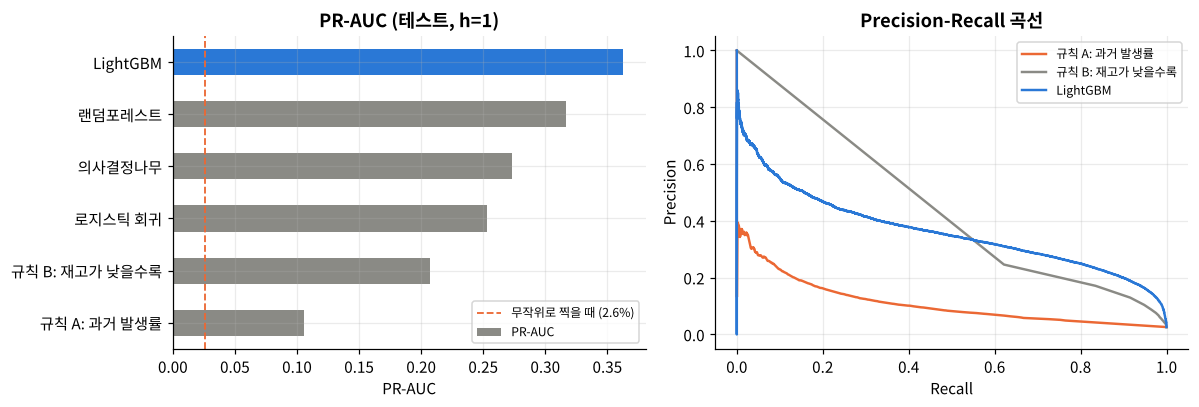

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = res1["PR-AUC"].sort_values()
order.plot.barh(ax=ax[0], color=[BLUE if i == "LightGBM" else GRAY for i in order.index])
ax[0].axvline(te[y].mean(), color=ORANGE, ls="--", lw=1.2, label=f"무작위로 찍을 때 ({te[y].mean():.1%})")
ax[0].legend(loc="lower right", fontsize=8)
ax[0].set(title="PR-AUC (테스트, h=1)", xlabel="PR-AUC", ylabel="")
for name, s in scores.items():
    P, R, _ = precision_recall_curve(yt, s)
    ax[1].plot(R, P, label=name, lw=1.6, color={"LightGBM": BLUE}.get(name, ORANGE if "A" in name else GRAY))
ax[1].set(title="Precision-Recall 곡선", xlabel="Recall", ylabel="Precision"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "model_01_h1_comparison.png", bbox_inches="tight"); plt.show()

## 2. 예측 시점별 성능 (h = 1, 2, 3시간 뒤) — LightGBM

In [6]:
rows, models = [], {1: m1}
for h in (1, 2, 3):
    tr_h, va_h, te_h, y_h = make_sets(h)
    m = models[h] if h in models else fit_lgb(tr_h, va_h, y_h)
    models[h] = m
    yv_h, yt_h = va_h[y_h].values, te_h[y_h].values
    r = evaluate("LightGBM", yv_h, m.predict_proba(va_h[FEATS])[:, 1], yt_h, m.predict_proba(te_h[FEATS])[:, 1])
    ra = evaluate("규칙 A", yv_h, va_h[f"hist_rate_h{h}"].values, yt_h, te_h[f"hist_rate_h{h}"].values)
    rb = evaluate("규칙 B", yv_h, -va_h["stock"].values, yt_h, -te_h["stock"].values)
    for r_ in (rb, ra, r):
        rows.append({"시점": f"{h}시간 뒤", "사건 비율": yt_h.mean(), **r_})
res_h = pd.DataFrame(rows).round(4)
res_h.to_csv(ROOT / "reports" / "model_by_horizon.csv", index=False, encoding="utf-8-sig")
res_h

,시점,사건 비율,모델,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
0,1시간 뒤,0.0260,규칙 B,0.2069,0.9311,0.2461,0.6217,0.3526,0.9407
1,1시간 뒤,0.0260,규칙 A,0.1055,0.7431,0.1471,0.2348,0.1808,0.9448
2,1시간 뒤,0.0260,LightGBM,0.3626,0.9588,0.3348,0.5444,0.4146,0.9601
3,2시간 뒤,0.0398,규칙 B,0.2466,0.9059,0.3095,0.5097,0.3852,0.9352
4,2시간 뒤,0.0398,규칙 A,0.1689,0.7652,0.2129,0.2868,0.2443,0.9294
5,2시간 뒤,0.0398,LightGBM,0.4212,0.9479,0.3827,0.5590,0.4544,0.9465
6,3시간 뒤,0.0506,규칙 B,0.2641,0.8855,0.2645,0.6616,0.3780,0.8898
7,3시간 뒤,0.0506,규칙 A,0.2129,0.7760,0.2518,0.3197,0.2817,0.9175
8,3시간 뒤,0.0506,LightGBM,0.4599,0.9408,0.4108,0.5706,0.4777,0.9369


## 3. Feature Importance — 어떤 변수가 가장 중요한가 (LightGBM, gain 기준)

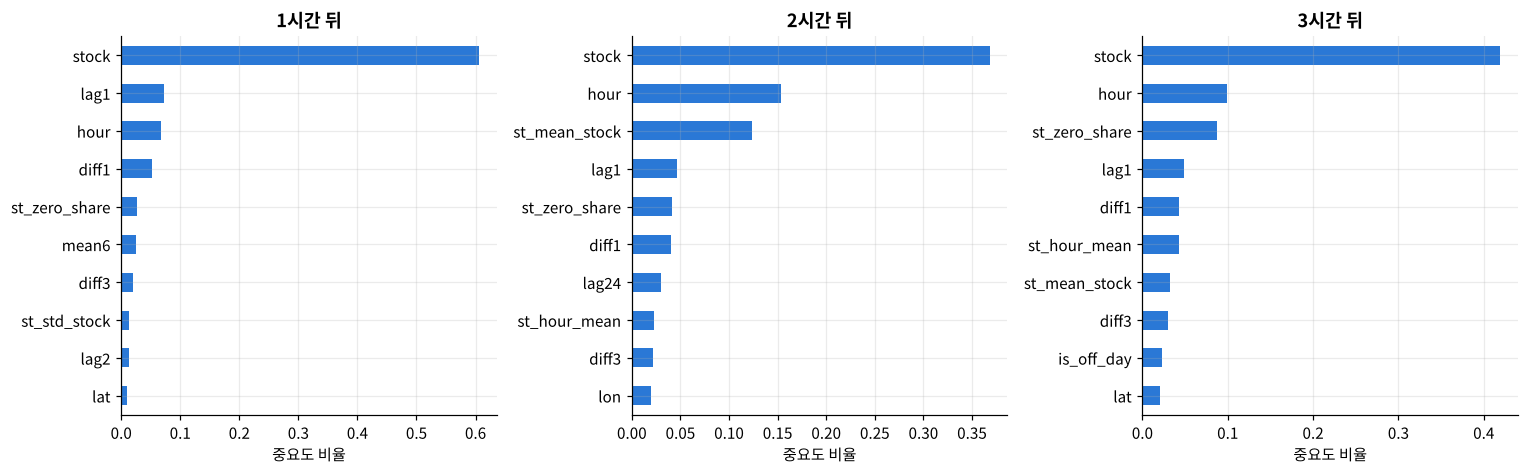

1시간 뒤: 1위 stock (60.6%), 2위 lag1 (7.2%)
2시간 뒤: 1위 stock (36.8%), 2위 hour (15.3%)
3시간 뒤: 1위 stock (41.9%), 2위 hour (9.9%)
날씨 변수 합계(h=1): 3.4%


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), sharex=False)
imp_all = {}
for a, h in zip(ax, (1, 2, 3)):
    imp = pd.Series(models[h].booster_.feature_importance("gain"), index=FEATS)
    imp = (imp / imp.sum()).sort_values(ascending=False)
    imp_all[h] = imp
    imp.head(10)[::-1].plot.barh(ax=a, color=BLUE)
    a.set(title=f"{h}시간 뒤", xlabel="중요도 비율")
plt.tight_layout(); plt.savefig(FIG / "model_02_feature_importance.png", bbox_inches="tight"); plt.show()
for h in (1, 2, 3):
    top = imp_all[h].head(2)
    print(f"{h}시간 뒤: 1위 {top.index[0]} ({top.iloc[0]:.1%}), 2위 {top.index[1]} ({top.iloc[1]:.1%})")
weather = ["temp", "rain", "rain_3h", "humid", "wind", "snow", "temp_diff_3h"]
print("날씨 변수 합계(h=1):", f"{imp_all[1][weather].sum():.1%}")

## 4. 체크포인트 판단

**결과 요약 (h=1, 테스트 구간 12/11~12/31)**

| | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| 무작위(사건 비율) | 0.026 | - | - | - |
| 규칙 B (재고 낮을수록) | 0.207 | 0.246 | 0.622 | 0.353 |
| LightGBM | **0.363** | **0.335** | 0.544 | **0.415** |

- **체크포인트 기준(PR-AUC 0.21 초과)을 통과했다.** LightGBM은 가장 강한 규칙 베이스라인의 약 1.75배, 무작위의 약 14배다. 모델 순위는 LightGBM > 랜덤포레스트 > 의사결정나무 > 로지스틱 회귀 > 규칙 B > 규칙 A(PR-AUC 기준)다. 따라서 **주제를 유지한다.**
- **절대 성능은 아직 보수적으로 읽어야 한다.** 알림 3번 중 1번 정도만 실제 부족으로 이어진다(Precision 0.335). 정확도는 0.96이지만, '전부 부족하지 않다'고 답해도 97.4%가 나오는 문제라 의미가 없다.
- **중요 변수:** 1위는 세 시점 모두 현재 재고(`stock`)이고, 2위는 1시간 뒤에는 1시간 전 재고(`lag1`), 2·3시간 뒤에는 시간대(`hour`)다. 날씨 변수 전체의 기여는 h=1에서 3.4%로 작다. 날씨 영향이 현재 재고에 이미 반영되어 있거나, 비 오는 표본이 적어서일 수 있다(해석).
- 시점이 멀수록 PR-AUC가 올라가는 것은 사건 비율이 커지기 때문이기도 하니, 시점끼리 단순 비교하지 않는다.
- 규칙 B의 PR 곡선이 직선처럼 보이는 것은 재고가 정수라 같은 점수가 많기 때문이다.

**한계와 다음 단계**
- 테스트 구간의 사건 비율(2.6%)이 학습 구간(3.65%)보다 낮다. 12월 한파로 이용이 줄어든 분포 변화가 있어, 검증 구간에서 고른 임계값이 테스트에서는 최적이 아닐 수 있다. 보고서 한계점에 적는다.
- 다음: GridSearchCV로 하이퍼파라미터 튜닝(RF, XGBoost, LightGBM), 오류 분석(어떤 대여소·시간대를 놓치는가), 실행 제언 정리.